# Fase 8: Prueba con la realidad — temporada 2025/26
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025
**Objetivo:** Probar los modelos contra partidos que **nunca se usaron en ninguna decisión del proyecto** (ni en la selección de variables, ni en el ajuste de modelos): la temporada 2025/26 completa.
**Input:** `Dataset/prueba_2025_26/` (generado por `soccerdata/preparar_2025_26.py`)
**Output:** `resultados/prueba_real_2025_26_*.csv`, `Imagenes/prueba_real/*.png`

## Protocolo (fijado ANTES de ver los resultados)
1. **Entrenamiento:** los 2.973 partidos de 2017/18 a 2024/25. **Prueba:** los 377 partidos evaluables de 2025/26 (3 partidos de Sunderland, recién ascendido y sin historial en la liga, se excluyen por la misma regla que el resto del proyecto).
2. **Variables:** las 28 seleccionadas en `03_feature_selection.ipynb` (elegidas con datos hasta 2024/25).
3. **Modelos:** (a) **Random Forest** con la misma grilla y criterio que `04_tuning.ipynb` (F1, `TimeSeriesSplit` interno de 3 folds); (b) **solo cuotas**, regresión logística sobre las 3 probabilidades implícitas, con C elegido por log-loss; (c) **regla simple del mercado**: local si P(local) > P(visitante).
4. **Nada se ajusta con 2025/26.** Además de un modelo entrenado una sola vez, se evalúa una variante *walk-forward* que **reentrena 4 veces durante la temporada** con los hiperparámetros ya fijados, como se haría en la práctica.
5. Se reporta todo lo calculado, con intervalos de confianza y pruebas de significancia (McNemar), porque con 377 partidos el accuracy tiene un error estándar de ~2,4 puntos.

## 1. Carga y verificación de los datos

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, brier_score_loss, log_loss, confusion_matrix
from sklearn.calibration import calibration_curve

sns.set_theme(style='whitegrid', palette='muted'); plt.rcParams['figure.dpi'] = 120
os.makedirs('Imagenes/prueba_real', exist_ok=True)
TARGET, TEMP = 'target_home_win', '2025-2026'
D = 'Dataset/prueba_2025_26/'

en = pd.read_csv(D + 'model_dataset_enriched.csv')
res = pd.read_csv(D + 'model_dataset.csv')[['season', 'home', 'away', 'home_goals', 'away_goals', 'result']]
SEL = [c for c in pd.read_csv('Dataset/model_dataset_selected.csv', nrows=1).columns if c not in (TARGET, 'season')]
CUOTAS = ['odds_home_prob', 'odds_draw_prob', 'odds_away_prob']

train = pd.read_csv('Dataset/model_dataset_enriched.csv')   # exactamente los datos ya validados, en su orden original
test = en[en['season'] == TEMP].sort_values('date').reset_index(drop=True)
test = test.merge(res, on=['season', 'home', 'away'], how='left')
# los datos de entrenamiento son exactamente los ya validados del proyecto
orig = pd.read_csv('Dataset/model_dataset_selected.csv')
assert len(train) == len(orig) and np.allclose(train[SEL].values, orig[SEL].values) and (train[TARGET].values == orig[TARGET].values).all()
# y los partidos de 2017-2025 del archivo de la prueba son los mismos (se verificó en preparar_2025_26.py)
assert set(zip(train.home, train.away, train.season)) == set(zip(en[en.season != TEMP].home, en[en.season != TEMP].away, en[en.season != TEMP].season))
print(f'Entrenamiento: {len(train)} partidos (2017/18-2024/25) | Prueba: {len(test)} partidos de 2025/26 ({test.date.min()} a {test.date.max()})')
print(f'Victorias locales: entrenamiento {train[TARGET].mean()*100:.1f}% | 2025/26 {test[TARGET].mean()*100:.1f}%')
print('Resultados reales 2025/26:', test['result'].value_counts().to_dict())

Entrenamiento: 2973 partidos (2017/18-2024/25) | Prueba: 377 partidos de 2025/26 (2025-08-15 a 2026-05-24)
Victorias locales: entrenamiento 44.2% | 2025/26 42.2%
Resultados reales 2025/26: {'H': 159, 'A': 114, 'D': 104}


## 2. Modelos entrenados una sola vez con 2017/18–2024/25
La grilla del Random Forest es la misma de `04_tuning.ipynb`.

In [2]:
t0 = time.time()
GRID = {'n_estimators': [200, 400, 600], 'max_depth': [8, 12, 16, None], 'min_samples_leaf': [2, 4, 8]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=1, class_weight='balanced'), GRID,
                     cv=TimeSeriesSplit(3), scoring='f1', n_jobs=-1).fit(train[SEL], train[TARGET])
gs_lr = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), {'logisticregression__C': [0.01, 0.1, 1, 10]},
                     cv=TimeSeriesSplit(3), scoring='neg_log_loss').fit(train[CUOTAS], train[TARGET])
BEST_RF, BEST_C = gs_rf.best_params_, gs_lr.best_params_['logisticregression__C']
print(f'Random Forest: {BEST_RF} (F1 interno {gs_rf.best_score_:.4f}) | Solo cuotas: C={BEST_C} | {time.time()-t0:.0f}s')

test['p_rf'] = gs_rf.predict_proba(test[SEL])[:, 1]
test['p_cuotas'] = gs_lr.predict_proba(test[CUOTAS])[:, 1]
test['pred_mercado'] = (test['odds_home_prob'] > test['odds_away_prob']).astype(int)

Random Forest: {'max_depth': 12, 'min_samples_leaf': 4, 'n_estimators': 400} (F1 interno 0.6305) | Solo cuotas: C=10 | 39s


## 3. Variante walk-forward (reentrenar durante la temporada)
En la práctica el modelo se actualizaría con los partidos ya jugados. Se divide 2025/26 en 4 bloques cronológicos (~10 jornadas cada uno); para cada bloque se reentrena con todo lo anterior (entrenamiento + bloques previos), **con los mismos hiperparámetros ya fijados**.

In [3]:
bloques = np.array_split(np.arange(len(test)), 4)
p_rf_wf, p_cu_wf = np.zeros(len(test)), np.zeros(len(test))
for k, idx in enumerate(bloques):
    previo = pd.concat([train, test.iloc[:idx[0]][train.columns]], ignore_index=True)
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced', **BEST_RF).fit(previo[SEL], previo[TARGET])
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=BEST_C, max_iter=2000)).fit(previo[CUOTAS], previo[TARGET])
    p_rf_wf[idx] = rf.predict_proba(test.loc[idx, SEL])[:, 1]; p_cu_wf[idx] = lr.predict_proba(test.loc[idx, CUOTAS])[:, 1]
    print(f'bloque {k+1}: partidos {idx[0]+1}-{idx[-1]+1} | entrenado con {len(previo)} partidos')
test['p_rf_wf'], test['p_cuotas_wf'] = p_rf_wf, p_cu_wf

bloque 1: partidos 1-95 | entrenado con 2973 partidos


bloque 2: partidos 96-189 | entrenado con 3068 partidos


bloque 3: partidos 190-283 | entrenado con 3162 partidos


bloque 4: partidos 284-377 | entrenado con 3256 partidos


## 4. Resultados frente a la realidad

In [4]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

y = test[TARGET].values
modelos = {'Random Forest': test['p_rf'].values, 'Random Forest (walk-forward)': test['p_rf_wf'].values,
           'Solo cuotas': test['p_cuotas'].values, 'Solo cuotas (walk-forward)': test['p_cuotas_wf'].values}
filas = []
for nombre, p in modelos.items():
    pred = (p >= 0.5).astype(int); k = int((pred == y).sum()); lo, hi = wilson(k, len(y))
    filas.append({'modelo': nombre, 'accuracy': k / len(y), 'ic95_inf': lo, 'ic95_sup': hi, 'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, p),
                  'brier': brier_score_loss(y, p), 'log_loss': log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), 'aciertos': k})
k = int((test['pred_mercado'] == y).sum()); lo, hi = wilson(k, len(y))
filas.append({'modelo': 'Mercado (regla simple)', 'accuracy': k / len(y), 'ic95_inf': lo, 'ic95_sup': hi, 'f1': f1_score(y, test['pred_mercado']),
              'roc_auc': np.nan, 'brier': np.nan, 'log_loss': np.nan, 'aciertos': k})
tabla = pd.DataFrame(filas).set_index('modelo')
tabla.round(4).to_csv('resultados/prueba_real_2025_26_resumen.csv')
print(f'PRUEBA REAL 2025/26 — {len(y)} partidos'); print(tabla.round(4).to_string())
ref = pd.read_csv('resultados/comparacion_con_keras_tuner.csv', index_col='model')
print('\nReferencia (promedio de los 7 folds de 2018-2025): Random Forest accuracy %.4f, AUC %.4f | Solo cuotas accuracy %.4f, AUC %.4f' % (
    ref.loc['Random Forest', 'accuracy_mean'], ref.loc['Random Forest', 'roc_auc_mean'], ref.loc['Solo cuotas (Reg. Logística)', 'accuracy_mean'], ref.loc['Solo cuotas (Reg. Logística)', 'roc_auc_mean']))

PRUEBA REAL 2025/26 — 377 partidos
                              accuracy  ic95_inf  ic95_sup      f1  roc_auc   brier  log_loss  aciertos
modelo                                                                                                 
Random Forest                   0.6127    0.5627    0.6605  0.5350   0.6725  0.2240    0.6355       231
Random Forest (walk-forward)    0.6207    0.5707    0.6682  0.5517   0.6690  0.2250    0.6376       234
Solo cuotas                     0.6286    0.5788    0.6759  0.5425   0.6971  0.2157    0.6186       237
Solo cuotas (walk-forward)      0.6286    0.5788    0.6759  0.5425   0.6964  0.2157    0.6187       237
Mercado (regla simple)          0.6048    0.5546    0.6528  0.6266      NaN     NaN       NaN       228

Referencia (promedio de los 7 folds de 2018-2025): Random Forest accuracy 0.6824, AUC 0.7266 | Solo cuotas accuracy 0.6767, AUC 0.7358


## 5. ¿Las diferencias son reales? Prueba de McNemar (pares de modelos sobre los mismos partidos)
Solo cuentan los partidos donde un modelo acierta y el otro falla.

In [5]:
def mcnemar(a, b):
    ok_a, ok_b = (a == y), (b == y)
    n10, n01 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    p = binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if (n10 + n01) else 1.0
    return n10, n01, p

preds = {'RF': (test['p_rf'] >= .5).astype(int).values, 'RF-wf': (test['p_rf_wf'] >= .5).astype(int).values,
         'Cuotas': (test['p_cuotas'] >= .5).astype(int).values, 'Mercado': test['pred_mercado'].values}
pares = [('RF', 'Mercado'), ('Cuotas', 'Mercado'), ('RF', 'Cuotas'), ('RF-wf', 'RF')]
mc = []
for a, b in pares:
    n10, n01, p = mcnemar(preds[a], preds[b])
    mc.append({'A': a, 'B': b, 'solo_A_acierta': n10, 'solo_B_acierta': n01, 'dif_acc_pp': (preds[a] == y).mean() * 100 - (preds[b] == y).mean() * 100, 'p_valor': p})
mc = pd.DataFrame(mc); mc.round(4).to_csv('resultados/prueba_real_2025_26_mcnemar.csv', index=False)
print(mc.round(4).to_string(index=False))
print('\nCon p < 0,05 la diferencia no se explicaría por azar.')

     A       B  solo_A_acierta  solo_B_acierta  dif_acc_pp  p_valor
    RF Mercado              45              42      0.7958   0.8304
Cuotas Mercado              51              42      2.3873   0.4069
    RF  Cuotas              11              17     -1.5915   0.3449
 RF-wf      RF               6               3      0.7958   0.5078

Con p < 0,05 la diferencia no se explicaría por azar.


## 6. Dónde acierta y dónde falla: por tipo de resultado real, mes y confianza

In [6]:
test['pred_rf'] = (test['p_rf'] >= .5).astype(int); test['ok_rf'] = (test['pred_rf'] == y).astype(int)
test['ok_mercado'] = (test['pred_mercado'] == y).astype(int); test['pred_cu'] = (test['p_cuotas'] >= .5).astype(int); test['ok_cu'] = (test['pred_cu'] == y).astype(int)
test['mes'] = pd.to_datetime(test['date']).dt.to_period('M').astype(str)

print('Por resultado real (el empate cuenta como "no gana el local"):')
por_res = test.groupby('result')[['ok_rf', 'ok_cu', 'ok_mercado']].agg(['mean']).round(3); por_res.columns = ['RF', 'Solo cuotas', 'Mercado']
por_res.insert(0, 'partidos', test.groupby('result').size()); print(por_res.to_string())
print('\nPor mes:'); por_mes = test.groupby('mes')[['ok_rf', 'ok_cu', 'ok_mercado']].mean().round(3); por_mes.columns = ['RF', 'Solo cuotas', 'Mercado']
por_mes.insert(0, 'partidos', test.groupby('mes').size()); print(por_mes.to_string())
test['confianza'] = pd.cut(np.abs(test['p_rf'] - .5), [-.001, .1, .2, .3, .5], labels=['baja (45-55%)', 'media (55-65%)', 'alta (65-80%)', 'muy alta (>80%)'])
print('\nPor confianza del Random Forest:'); por_conf = test.groupby('confianza', observed=True).agg(partidos=('ok_rf', 'size'), accuracy=('ok_rf', 'mean')).round(3); print(por_conf.to_string())
por_res.to_csv('resultados/prueba_real_2025_26_por_resultado.csv'); por_mes.to_csv('resultados/prueba_real_2025_26_por_mes.csv')

Por resultado real (el empate cuenta como "no gana el local"):
        partidos     RF  Solo cuotas  Mercado
result                                       
A            114  0.711        0.772    0.526
D            104  0.635        0.635    0.413
H            159  0.528        0.522    0.786

Por mes:
         partidos     RF  Solo cuotas  Mercado
mes                                           
2025-08        27  0.593        0.556    0.556
2025-09        30  0.600        0.567    0.567
2025-10        30  0.567        0.633    0.600
2025-11        40  0.675        0.675    0.750
2025-12        56  0.607        0.607    0.643
2026-01        49  0.510        0.551    0.551
2026-02        42  0.667        0.762    0.595
2026-03        32  0.594        0.594    0.469
2026-04        30  0.667        0.767    0.600
2026-05        41  0.659        0.585    0.659

Por confianza del Random Forest:
                 partidos  accuracy
confianza                          
baja (45-55%)         122  

## 7. Los errores más confiados

In [7]:
test['error_conf'] = np.abs(test['p_rf'] - y)
top = test[test['ok_rf'] == 0].sort_values('error_conf', ascending=False).head(12)[['date', 'home', 'away', 'home_goals', 'away_goals', 'result', 'p_rf', 'p_cuotas', 'odds_home_prob']]
top['marcador'] = top['home_goals'].astype(int).astype(str) + '-' + top['away_goals'].astype(int).astype(str)
print(top[['date', 'home', 'away', 'marcador', 'p_rf', 'p_cuotas', 'odds_home_prob']].round(3).to_string(index=False))
cols = ['date', 'home', 'away', 'home_goals', 'away_goals', 'result', TARGET, 'odds_home_prob', 'odds_draw_prob', 'odds_away_prob', 'p_rf', 'p_cuotas', 'p_rf_wf', 'p_cuotas_wf', 'pred_mercado']
test[cols].to_csv('resultados/prueba_real_2025_26_predicciones.csv', index=False)
print('\nPredicciones guardadas: resultados/prueba_real_2025_26_predicciones.csv')

      date             home            away marcador  p_rf  p_cuotas  odds_home_prob
2025-12-03     Leeds United         Chelsea      3-1 0.162     0.225           0.244
2025-10-26      Aston Villa Manchester City      1-0 0.166     0.212           0.231
2026-01-17        Liverpool         Burnley      1-1 0.801     0.772           0.820
2025-08-31         Brighton Manchester City      2-1 0.237     0.240           0.263
2026-05-17          Everton      Sunderland      1-3 0.762     0.536           0.556
2025-10-25        Brentford       Liverpool      3-2 0.240     0.217           0.244
2026-03-03           Wolves       Liverpool      2-1 0.244     0.161           0.182
2026-02-21          Chelsea         Burnley      1-1 0.755     0.778           0.820
2025-11-22 Newcastle United Manchester City      2-1 0.246     0.246           0.278
2025-10-18          Burnley    Leeds United      2-0 0.249     0.272           0.308
2025-12-03        Liverpool      Sunderland      1-1 0.737     0.

## 8. Gráficos

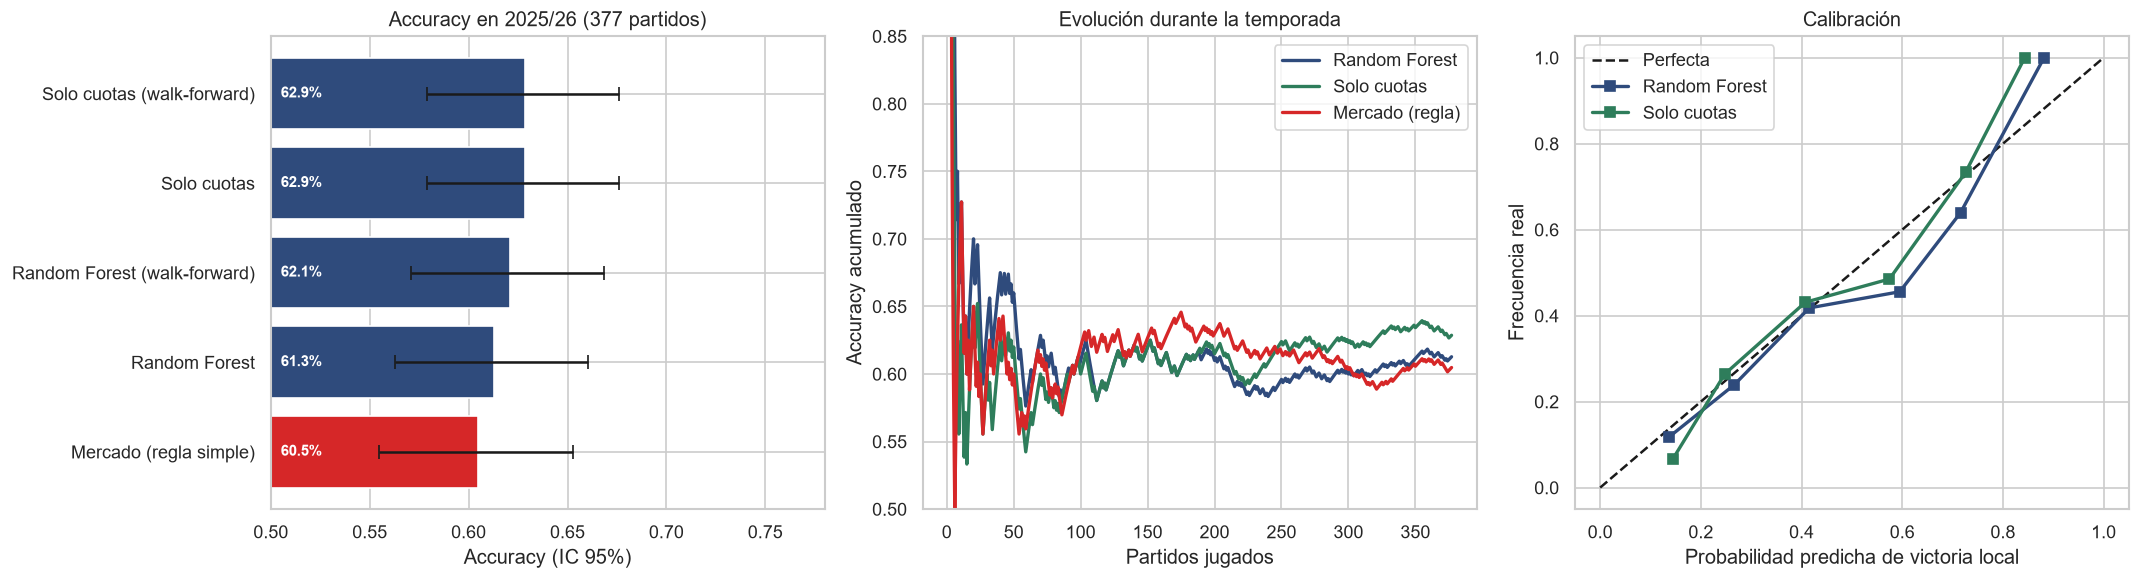

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (a) accuracy con intervalo de confianza
t = tabla['accuracy'].sort_values(); ax = axes[0]
err = np.array([t.values - tabla.loc[t.index, 'ic95_inf'].values, tabla.loc[t.index, 'ic95_sup'].values - t.values])
ax.barh(t.index, t.values, xerr=err, color=['#d62728' if 'Mercado' in i else '#2F4B7C' for i in t.index], capsize=4)
for i, v in enumerate(t.values): ax.text(0.505, i, f'{v*100:.1f}%', va='center', color='white', fontsize=9, fontweight='bold')
ax.set_xlim(0.5, 0.78); ax.set_xlabel('Accuracy (IC 95%)'); ax.set_title('Accuracy en 2025/26 (377 partidos)')
# (b) acierto acumulado durante la temporada
ax = axes[1]
for col, lab, c in [('ok_rf', 'Random Forest', '#2F4B7C'), ('ok_cu', 'Solo cuotas', '#2E7D5B'), ('ok_mercado', 'Mercado (regla)', '#d62728')]:
    ax.plot(np.arange(1, len(test) + 1), test[col].expanding().mean().values, label=lab, color=c, lw=2)
ax.axhline(0.5, color='gray', ls=':'); ax.set_ylim(0.5, 0.85); ax.set_xlabel('Partidos jugados'); ax.set_ylabel('Accuracy acumulado'); ax.set_title('Evolución durante la temporada'); ax.legend()
# (c) calibración
ax = axes[2]; ax.plot([0, 1], [0, 1], 'k--', label='Perfecta')
for col, lab, c in [('p_rf', 'Random Forest', '#2F4B7C'), ('p_cuotas', 'Solo cuotas', '#2E7D5B')]:
    pt, pp = calibration_curve(y, test[col], n_bins=6); ax.plot(pp, pt, 's-', label=lab, color=c, lw=2)
ax.set_xlabel('Probabilidad predicha de victoria local'); ax.set_ylabel('Frecuencia real'); ax.set_title('Calibración'); ax.legend()
plt.tight_layout(); plt.savefig('Imagenes/prueba_real/resumen_2025_26.png', bbox_inches='tight', dpi=120); plt.show()

## 9. Resumen

In [9]:
rf, cu, me = tabla.loc['Random Forest'], tabla.loc['Solo cuotas'], tabla.loc['Mercado (regla simple)']
print('=' * 78); print(' RESUMEN — PRUEBA REAL CON LA TEMPORADA 2025/26'); print('=' * 78)
print(f' Partidos evaluados: {len(y)}  (entrenamiento: {len(train)} partidos de 2017/18 a 2024/25)')
print(f' Random Forest : accuracy {rf.accuracy*100:.1f}% (IC95% {rf.ic95_inf*100:.1f}-{rf.ic95_sup*100:.1f}) | AUC {rf.roc_auc:.3f} | log-loss {rf.log_loss:.3f}')
print(f' Solo cuotas   : accuracy {cu.accuracy*100:.1f}% (IC95% {cu.ic95_inf*100:.1f}-{cu.ic95_sup*100:.1f}) | AUC {cu.roc_auc:.3f} | log-loss {cu.log_loss:.3f}')
print(f' Mercado (regla): accuracy {me.accuracy*100:.1f}% (IC95% {me.ic95_inf*100:.1f}-{me.ic95_sup*100:.1f})')
print(f' RF vs mercado: {mc.iloc[0].dif_acc_pp:+.1f} pp, McNemar p = {mc.iloc[0].p_valor:.3f} | Solo cuotas vs mercado: {mc.iloc[1].dif_acc_pp:+.1f} pp, p = {mc.iloc[1].p_valor:.3f}')
print('=' * 78)

 RESUMEN — PRUEBA REAL CON LA TEMPORADA 2025/26
 Partidos evaluados: 377  (entrenamiento: 2973 partidos de 2017/18 a 2024/25)
 Random Forest : accuracy 61.3% (IC95% 56.3-66.1) | AUC 0.672 | log-loss 0.636
 Solo cuotas   : accuracy 62.9% (IC95% 57.9-67.6) | AUC 0.697 | log-loss 0.619
 Mercado (regla): accuracy 60.5% (IC95% 55.5-65.3)
 RF vs mercado: +0.8 pp, McNemar p = 0.830 | Solo cuotas vs mercado: +2.4 pp, p = 0.407
